In [25]:
import os

dataset_path = "../dataset/Respiratory_Sound_Database/Respiratory_Sound_Database/Respiratory_Sound_Database/audio_and_txt_files"

print(os.path.exists(dataset_path))

True


In [26]:
import os

files = os.listdir(dataset_path)

print("Total files:", len(files))
print("First 10 files:")
print(files[:10])

Total files: 1840
First 10 files:
['101_1b1_Al_sc_Meditron.txt', '101_1b1_Al_sc_Meditron.wav', '101_1b1_Pr_sc_Meditron.txt', '101_1b1_Pr_sc_Meditron.wav', '102_1b1_Ar_sc_Meditron.txt', '102_1b1_Ar_sc_Meditron.wav', '103_2b2_Ar_mc_LittC2SE.txt', '103_2b2_Ar_mc_LittC2SE.wav', '104_1b1_Al_sc_Litt3200.txt', '104_1b1_Al_sc_Litt3200.wav']


In [27]:
wav_files = [f for f in files if f.endswith(".wav")]
txt_files = [f for f in files if f.endswith(".txt")]

print("WAV files:", len(wav_files))
print("TXT files:", len(txt_files))

WAV files: 920
TXT files: 920


In [28]:
import pandas as pd

diagnosis_path = "../dataset/Respiratory_Sound_Database/Respiratory_Sound_Database/Respiratory_Sound_Database/patient_diagnosis.csv"

diagnosis = pd.read_csv(diagnosis_path, header=None)

print(diagnosis.head())
print("\nTotal patients:", len(diagnosis))

     0        1
0  101     URTI
1  102  Healthy
2  103   Asthma
3  104     COPD
4  105     URTI

Total patients: 126


In [29]:
print(diagnosis[1].value_counts())

1
COPD              64
Healthy           26
URTI              14
Bronchiectasis     7
Pneumonia          6
Bronchiolitis      6
LRTI               2
Asthma             1
Name: count, dtype: int64


In [30]:
sample_txt = os.path.join(dataset_path, txt_files[0])

with open(sample_txt, "r") as file:
    print(file.read())

0.036	0.579	0	0
0.579	2.45	0	0
2.45	3.893	0	0
3.893	5.793	0	0
5.793	7.521	0	0
7.521	9.279	0	0
9.279	11.15	0	0
11.15	13.036	0	0
13.036	14.721	0	0
14.721	16.707	0	0
16.707	18.507	0	0
18.507	19.964	0	0



In [31]:
import librosa

sample_wav = os.path.join(dataset_path, wav_files[0])

audio, sample_rate = librosa.load(sample_wav, sr=None)

print("Sample rate:", sample_rate)
print("Audio length:", len(audio))
print("Duration:", len(audio) / sample_rate, "seconds")

Sample rate: 44100
Audio length: 882000
Duration: 20.0 seconds


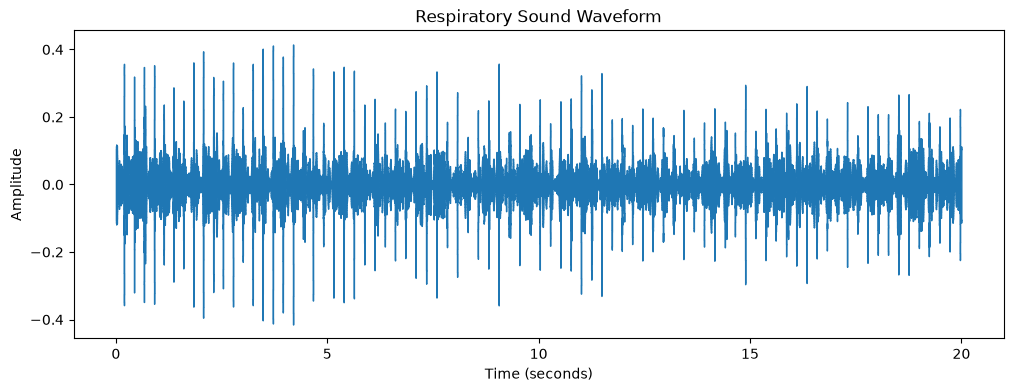

In [32]:
import matplotlib.pyplot as plt
import librosa.display

plt.figure(figsize=(12, 4))
librosa.display.waveshow(audio, sr=sample_rate)
plt.title("Respiratory Sound Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

In [33]:
mfcc = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=13)

print("MFCC shape:", mfcc.shape)

MFCC shape: (13, 1723)


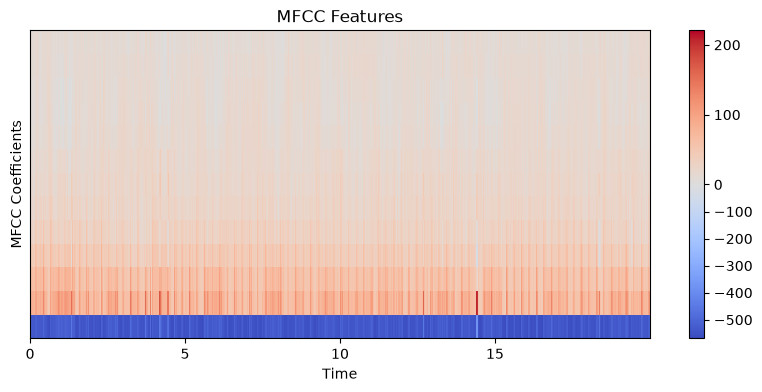

In [34]:
plt.figure(figsize=(10, 4))
librosa.display.specshow(mfcc, sr=sample_rate, x_axis="time")
plt.colorbar()
plt.title("MFCC Features")
plt.xlabel("Time")
plt.ylabel("MFCC Coefficients")
plt.show()

In [35]:
import numpy as np
mfcc_normalized = (mfcc - np.mean(mfcc)) / np.std(mfcc)

print("Normalized MFCC shape:", mfcc_normalized.shape)
print("Mean:", np.mean(mfcc_normalized))
print("Standard deviation:", np.std(mfcc_normalized))

Normalized MFCC shape: (13, 1723)
Mean: -1.0899622e-08
Standard deviation: 1.0


In [36]:
mfcc_features = np.mean(mfcc_normalized, axis=1)

print("Feature shape:", mfcc_features.shape)

Feature shape: (13,)


In [37]:
print(mfcc_features)

[-3.4242327   0.6182186   0.50233674  0.38139215  0.29854402  0.2584556
  0.23823874  0.2175703   0.19528656  0.1818479   0.180708    0.18125805
  0.17037596]


In [38]:
patient_id = int(wav_files[0].split("_")[0])
label = diagnosis[diagnosis[0] == patient_id][1].values[0]

print("Patient ID:", patient_id)
print("Disease:", label)

Patient ID: 101
Disease: URTI


In [39]:
def extract_mfcc(file_path):
    audio, sr = librosa.load(file_path, sr=None)
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)
    mfcc = (mfcc - np.mean(mfcc)) / np.std(mfcc)
    return np.mean(mfcc, axis=1)

In [40]:
X = []
y = []

for file in wav_files:
    file_path = os.path.join(dataset_path, file)
    
    features = extract_mfcc(file_path)
    
    patient_id = int(file.split("_")[0])
    label = diagnosis[diagnosis[0] == patient_id][1].values[0]
    
    X.append(features)
    y.append(label)

X = np.array(X)
y = np.array(y)

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (920, 13)
Labels shape: (920,)


In [41]:
print(pd.Series(y).value_counts())

COPD              793
Pneumonia          37
Healthy            35
URTI               23
Bronchiectasis     16
Bronchiolitis      13
LRTI                2
Asthma              1
Name: count, dtype: int64


In [42]:
print(pd.Series(y).value_counts()[pd.Series(y).value_counts() < 2])

Asthma    1
Name: count, dtype: int64


In [43]:
mask = y != "Asthma"

X = X[mask]
y = y[mask]

print("Features:", X.shape)
print("Labels:", y.shape)

Features: (919, 13)
Labels: (919,)


import os

dataset_path = "../dataset/Respiratory_Sound_Database/Respiratory_Sound_Database/Respiratory_Sound_Database/audio_and_txt_files"

print(os.path.exists(dataset_path))

In [44]:
# Imports and output folders
import os
import numpy as np
import pandas as pd
import librosa
import noisereduce as nr
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.utils.class_weight import compute_class_weight
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_score, recall_score, f1_score,
    roc_curve, auc, precision_recall_curve, average_precision_score
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.makedirs("../results", exist_ok=True)
os.makedirs("../models", exist_ok=True)

print("Dataset path exists:", os.path.isdir(dataset_path))
print("Diagnosis file loaded:", "diagnosis" in globals())

Dataset path exists: True
Diagnosis file loaded: True


In [45]:
# Build one labelled record per WAV file. Exclude the one-record Asthma class
# because it cannot be split reliably into both training and testing sets.
audio_records = []
for filename in sorted(f for f in os.listdir(dataset_path) if f.lower().endswith(".wav")):
    try:
        patient_id = int(filename.split("_")[0])
    except ValueError:
        continue
    matched = diagnosis.loc[diagnosis[0] == patient_id, 1]
    if matched.empty:
        continue
    label = str(matched.iloc[0])
    if label == "Asthma":
        continue
    audio_records.append({"filename": filename, "patient_id": patient_id, "label": label})

records_df = pd.DataFrame(audio_records)
if records_df.empty:
    raise ValueError("No labelled WAV recordings were found. Check dataset_path and patient_diagnosis.csv.")

print("Usable recordings:", len(records_df))
print(records_df["label"].value_counts())

Usable recordings: 919
label
COPD              793
Pneumonia          37
Healthy            35
URTI               23
Bronchiectasis     16
Bronchiolitis      13
LRTI                2
Name: count, dtype: int64


In [46]:
# Patient-level stratified split: recordings from one patient must not appear
# in both train and test, which would leak patient-specific information.
from sklearn.model_selection import StratifiedGroupKFold
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(
    splitter.split(records_df, records_df["label"], groups=records_df["patient_id"])
)
train_df = records_df.iloc[train_idx].reset_index(drop=True)
test_df = records_df.iloc[test_idx].reset_index(drop=True)

overlap = set(train_df["patient_id"]) & set(test_df["patient_id"])
if overlap:
    raise RuntimeError(f"Patient leakage detected: {sorted(overlap)}")
print("Patient-level split verified: no patient occurs in both sets.")

print("Training recordings:", len(train_df))
print("Testing recordings:", len(test_df))
print("\\nTraining labels:")
print(train_df["label"].value_counts())
print("\\nTest labels (not augmented):")
print(test_df["label"].value_counts())

Patient-level split verified: no patient occurs in both sets.
Training recordings: 736
Testing recordings: 183
\nTraining labels:
label
COPD              635
Healthy            28
Pneumonia          28
URTI               18
Bronchiectasis     14
Bronchiolitis      11
LRTI                2
Name: count, dtype: int64
\nTest labels (not augmented):
label
COPD              158
Pneumonia           9
Healthy             7
URTI                5
Bronchiolitis       2
Bronchiectasis      2
Name: count, dtype: int64


c:\Users\pooja\OneDrive\Documents\0-My life\Respiratory_Disease_Prediction\venv\Lib\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(


In [47]:
def load_and_reduce_audio(file_path):
    audio, sr = librosa.load(file_path, sr=None, mono=True)
    audio = nr.reduce_noise(y=audio, sr=sr, time_mask_smooth_ms=64)
    return audio.astype(np.float32), sr

def augment_audio(audio, rng):
    # Conservative amplitude and low-level noise changes.
    gain = rng.uniform(0.90, 1.10)
    augmented = audio * gain
    noise_level = rng.uniform(0.001, 0.004) * (np.std(augmented) + 1e-8)
    augmented = augmented + rng.normal(0, noise_level, size=augmented.shape)
    return np.clip(augmented, -1.0, 1.0).astype(np.float32)

def mfcc_vector_from_audio(audio, sr):
    # Do not z-score the complete MFCC matrix before averaging: that can
    # suppress useful absolute differences between recordings.
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)
    return np.mean(mfcc, axis=1).astype(np.float32)

def mfcc_matrix_from_audio(audio, sr, max_frames=1723):
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)
    # Per-recording normalization is used for the CNN's time-frequency map.
    mean = np.mean(mfcc)
    std = np.std(mfcc)
    mfcc = (mfcc - mean) / (std if std > 1e-8 else 1.0)
    if mfcc.shape[1] < max_frames:
        mfcc = np.pad(mfcc, ((0, 0), (0, max_frames - mfcc.shape[1])), mode="constant")
    else:
        mfcc = mfcc[:, :max_frames]
    return mfcc.astype(np.float32)

In [48]:
# Extract training features and augment minority-class recordings only.
rng = np.random.default_rng(SEED)
majority_label = train_df["label"].value_counts().idxmax()
X_train_list, y_train_list = [], []
X_cnn_train_list, y_cnn_train_list = [], []

for row in train_df.itertuples(index=False):
    audio, sr = load_and_reduce_audio(os.path.join(dataset_path, row.filename))
    X_train_list.append(mfcc_vector_from_audio(audio, sr))
    y_train_list.append(row.label)
    X_cnn_train_list.append(mfcc_matrix_from_audio(audio, sr))
    y_cnn_train_list.append(row.label)

    if row.label != majority_label:
        for _ in range(2):
            aug_audio = augment_audio(audio, rng)
            X_train_list.append(mfcc_vector_from_audio(aug_audio, sr))
            y_train_list.append(row.label)
            X_cnn_train_list.append(mfcc_matrix_from_audio(aug_audio, sr))
            y_cnn_train_list.append(row.label)

X_train_raw = np.asarray(X_train_list, dtype=np.float32)
y_train = np.asarray(y_train_list)
X_train_cnn = np.asarray(X_cnn_train_list, dtype=np.float32)[..., np.newaxis]
y_train_cnn = np.asarray(y_cnn_train_list)

# Extract the held-out test data once; never augment it.
X_test_list, y_test_list, X_cnn_test_list = [], [], []
for row in test_df.itertuples(index=False):
    audio, sr = load_and_reduce_audio(os.path.join(dataset_path, row.filename))
    X_test_list.append(mfcc_vector_from_audio(audio, sr))
    X_cnn_test_list.append(mfcc_matrix_from_audio(audio, sr))
    y_test_list.append(row.label)

X_test_raw = np.asarray(X_test_list, dtype=np.float32)
y_test = np.asarray(y_test_list)
X_test_cnn = np.asarray(X_cnn_test_list, dtype=np.float32)[..., np.newaxis]

print("Traditional training features:", X_train_raw.shape)
print("CNN training features:", X_train_cnn.shape)
print("Test features:", X_test_raw.shape)
print("\\nTraining labels after augmentation:")
print(pd.Series(y_train).value_counts())

Traditional training features: (938, 13)
CNN training features: (938, 13, 1723, 1)
Test features: (183, 13)
\nTraining labels after augmentation:
COPD              635
Healthy            84
Pneumonia          84
URTI               54
Bronchiectasis     42
Bronchiolitis      33
LRTI                6
Name: count, dtype: int64


In [49]:
# Fit the scaler on training data only; use the same transform for test data.
scaler_final = StandardScaler()
X_train_scaled = scaler_final.fit_transform(X_train_raw).astype(np.float32)
X_test_scaled = scaler_final.transform(X_test_raw).astype(np.float32)

label_encoder_final = LabelEncoder()
y_train_encoded = label_encoder_final.fit_transform(y_train)
y_test_encoded = label_encoder_final.transform(y_test)
y_train_cnn_encoded = label_encoder_final.transform(y_train_cnn)

classes = label_encoder_final.classes_
class_weights_array = compute_class_weight(
    class_weight="balanced", classes=np.unique(y_train_encoded), y=y_train_encoded
)
class_weights = dict(zip(np.unique(y_train_encoded), class_weights_array))

print("Classes:", list(classes))
print("Scaled feature shape:", X_train_scaled.shape)
print("Class weights:", class_weights)

Classes: [np.str_('Bronchiectasis'), np.str_('Bronchiolitis'), np.str_('COPD'), np.str_('Healthy'), np.str_('LRTI'), np.str_('Pneumonia'), np.str_('URTI')]
Scaled feature shape: (938, 13)
Class weights: {np.int64(0): np.float64(3.1904761904761907), np.int64(1): np.float64(4.0606060606060606), np.int64(2): np.float64(0.2110236220472441), np.int64(3): np.float64(1.5952380952380953), np.int64(4): np.float64(22.333333333333332), np.int64(5): np.float64(1.5952380952380953), np.int64(6): np.float64(2.4814814814814814)}


In [50]:
# Train traditional models. SVM uses scaled features; Random Forest uses raw features.
svm_final = SVC(
    probability=True, class_weight="balanced", kernel="rbf",
    random_state=SEED
)
svm_final.fit(X_train_scaled, y_train)
y_pred_svm_final = svm_final.predict(X_test_scaled)

rf_final = RandomForestClassifier(
    n_estimators=300, class_weight="balanced_subsample",
    random_state=SEED, n_jobs=-1
)
rf_final.fit(X_train_raw, y_train)
y_pred_rf_final = rf_final.predict(X_test_raw)

print("SVM accuracy:", f"{accuracy_score(y_test, y_pred_svm_final)*100:.2f}%")
print("Random Forest accuracy:", f"{accuracy_score(y_test, y_pred_rf_final)*100:.2f}%")

c:\Users\pooja\OneDrive\Documents\0-My life\Respiratory_Disease_Prediction\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM accuracy: 56.83%
Random Forest accuracy: 86.34%


In [51]:
# Train ANN on scaled feature vectors, with early stopping.
ann_final = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.25),
    Dense(32, activation="relu"),
    Dropout(0.15),
    Dense(len(classes), activation="softmax")
])
ann_final.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

ann_final.fit(
    X_train_scaled, y_train_encoded,
    epochs=40, batch_size=32, validation_split=0.2,
    class_weight=class_weights, callbacks=[early_stop], verbose=1
)
ann_prob_final = ann_final.predict(X_test_scaled, verbose=0)
y_pred_ann_final = label_encoder_final.inverse_transform(np.argmax(ann_prob_final, axis=1))
print("ANN accuracy:", f"{accuracy_score(y_test, y_pred_ann_final)*100:.2f}%")

Epoch 1/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.2667 - loss: 1.9136 - val_accuracy: 0.4415 - val_loss: 1.7872
Epoch 2/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3720 - loss: 1.8274 - val_accuracy: 0.4734 - val_loss: 1.7369
Epoch 3/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4320 - loss: 1.7040 - val_accuracy: 0.5213 - val_loss: 1.7000
Epoch 4/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4373 - loss: 1.6986 - val_accuracy: 0.5745 - val_loss: 1.6501
Epoch 5/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4613 - loss: 1.6526 - val_accuracy: 0.5585 - val_loss: 1.5928
Epoch 6/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4827 - loss: 1.6080 - val_accuracy: 0.5372 - val_loss: 1.5423
Epoch 7/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5173 - loss: 1.5923 - val_accuracy: 0.5266 - val_loss: 1.4993
Epoch 8/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5227 - loss: 1.5040 - val_accuracy: 0.5266 - val_loss

In [52]:
# CNN on MFCC matrices. GlobalAveragePooling2D keeps the model size manageable.
cnn_final = Sequential([
    Input(shape=(13, 1723, 1)),
    Conv2D(16, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    GlobalAveragePooling2D(),
    Dense(64, activation="relu"),
    Dropout(0.25),
    Dense(len(classes), activation="softmax")
])
cnn_final.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn_final.fit(
    X_train_cnn, y_train_cnn_encoded,
    epochs=20, batch_size=16, validation_split=0.2,
    class_weight=class_weights, callbacks=[early_stop], verbose=1
)
cnn_prob_final = cnn_final.predict(X_test_cnn, verbose=0)
y_pred_cnn_final = label_encoder_final.inverse_transform(np.argmax(cnn_prob_final, axis=1))
print("CNN accuracy:", f"{accuracy_score(y_test, y_pred_cnn_final)*100:.2f}%")

Epoch 1/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.4827 - loss: 1.8451 - val_accuracy: 0.0319 - val_loss: 1.9167
Epoch 2/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.3440 - loss: 1.8440 - val_accuracy: 0.0904 - val_loss: 1.9227
Epoch 3/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.3453 - loss: 1.8357 - val_accuracy: 0.0904 - val_loss: 1.9224
Epoch 4/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.2613 - loss: 1.8265 - val_accuracy: 0.1064 - val_loss: 1.9100
Epoch 5/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.3413 - loss: 1.8248 - val_accuracy: 0.1968 - val_loss: 1.8350
Epoch 6/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.4600 - loss: 1.8136 - val_accuracy: 0.1543 - val_loss: 1.8122
Epoch 7/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.4133 - loss: 1.7955 - val_accuracy: 0.2340 - val_loss: 1.7590
Epoch 8/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.3987 - loss: 1.7809 - val_accuracy: 0.4362 - v

In [53]:
# One consistent set of predictions drives all metrics and figures.
models_predictions = {
    "SVM": y_pred_svm_final,
    "Random Forest": y_pred_rf_final,
    "ANN": y_pred_ann_final,
    "CNN": y_pred_cnn_final
}
comparison_final = pd.DataFrame([
    {
        "Model": name,
        "Accuracy (%)": 100 * accuracy_score(y_test, pred),
        "Precision weighted": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall weighted": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1 weighted": f1_score(y_test, pred, average="weighted", zero_division=0),
        "F1 macro": f1_score(y_test, pred, average="macro", zero_division=0)
    }
    for name, pred in models_predictions.items()
])
print(comparison_final.round(4).to_string(index=False))

for name, pred in models_predictions.items():
    print(f"\\n===== {name} classification report =====")
    print(classification_report(y_test, pred, labels=classes, zero_division=0))

        Model  Accuracy (%)  Precision weighted  Recall weighted  F1 weighted  F1 macro
          SVM       56.8306              0.8661           0.5683       0.6655    0.2294
Random Forest       86.3388              0.7940           0.8634       0.8183    0.2184
          ANN       62.8415              0.8784           0.6284       0.7123    0.2667
          CNN       49.1803              0.8171           0.4918       0.5986    0.1289
\n===== SVM classification report =====
                precision    recall  f1-score   support

Bronchiectasis       0.10      0.50      0.17         2
 Bronchiolitis       0.00      0.00      0.00         2
          COPD       0.98      0.59      0.74       158
       Healthy       0.17      0.57      0.27         7
          LRTI       0.00      0.00      0.00         0
     Pneumonia       0.22      0.56      0.31         9
          URTI       0.09      0.20      0.12         5

      accuracy                           0.57       183
     macro avg

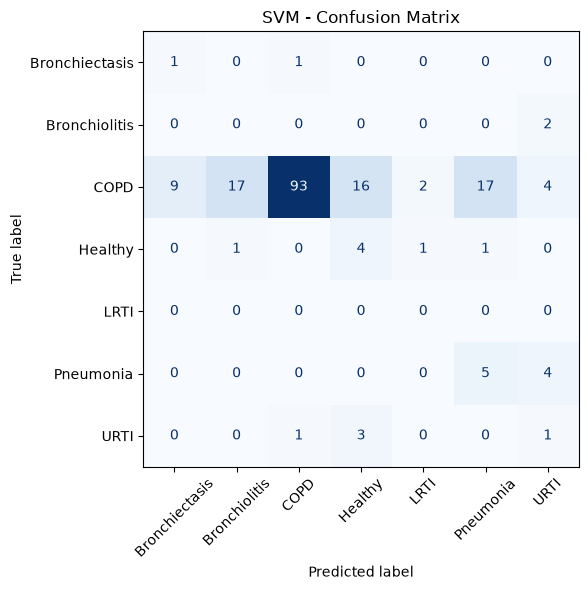

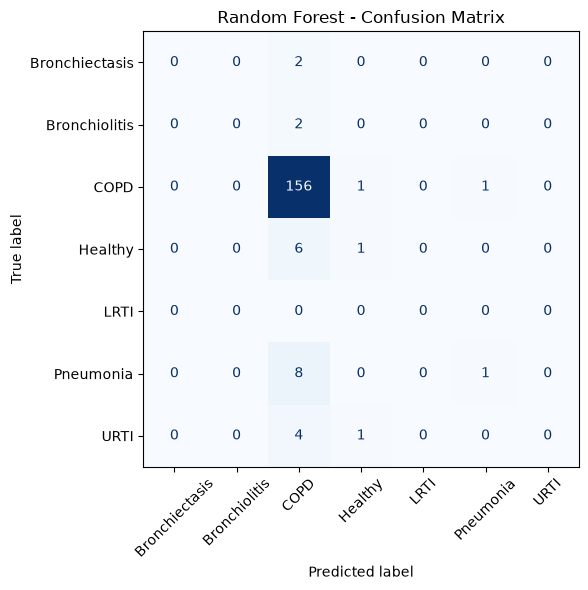

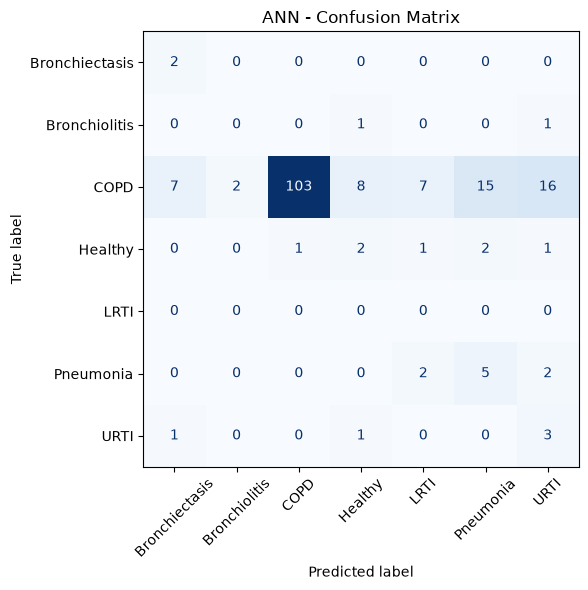

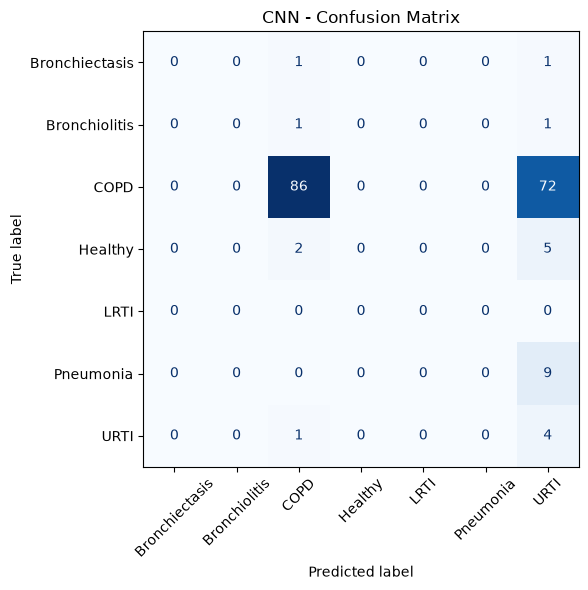

Saved confusion matrices and model_comparison.csv


In [54]:
# Confusion matrices, saved from the same predictions used in the table.
for name, pred in models_predictions.items():
    cm = confusion_matrix(y_test, pred, labels=classes)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
    fig, ax = plt.subplots(figsize=(8, 6))
    disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} - Confusion Matrix")
    fig.tight_layout()
    filename = name.lower().replace(" ", "_") + "_confusion_matrix.png"
    fig.savefig(f"../results/{filename}", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

comparison_final.to_csv("../results/model_comparison.csv", index=False)
print("Saved confusion matrices and model_comparison.csv")

In [57]:
print("Classes:", classes)
print("Binary labels:", y_test_bin.shape)

for name, probs in probabilities.items():
    print(name, "probability shape:", probs.shape)
    print("Rows match test set:", probs.shape[0] == len(y_test))
    print("Columns match classes:", probs.shape[1] == len(classes))
    print("Probabilities finite:", np.isfinite(probs).all())

Classes: ['Bronchiectasis' 'Bronchiolitis' 'COPD' 'Healthy' 'LRTI' 'Pneumonia'
 'URTI']
Binary labels: (183, 7)
SVM probability shape: (183, 7)
Rows match test set: True
Columns match classes: True
Probabilities finite: True
Random Forest probability shape: (183, 7)
Rows match test set: True
Columns match classes: True
Probabilities finite: True
ANN probability shape: (183, 7)
Rows match test set: True
Columns match classes: True
Probabilities finite: True
CNN probability shape: (183, 7)
Rows match test set: True
Columns match classes: True
Probabilities finite: True


In [58]:
print("SVM classes:", svm_final.classes_)
print("Random Forest classes:", rf_final.classes_)
print("Label encoder classes:", label_encoder_final.classes_)

SVM classes: ['Bronchiectasis' 'Bronchiolitis' 'COPD' 'Healthy' 'LRTI' 'Pneumonia'
 'URTI']
Random Forest classes: ['Bronchiectasis' 'Bronchiolitis' 'COPD' 'Healthy' 'LRTI' 'Pneumonia'
 'URTI']
Label encoder classes: ['Bronchiectasis' 'Bronchiolitis' 'COPD' 'Healthy' 'LRTI' 'Pneumonia'
 'URTI']


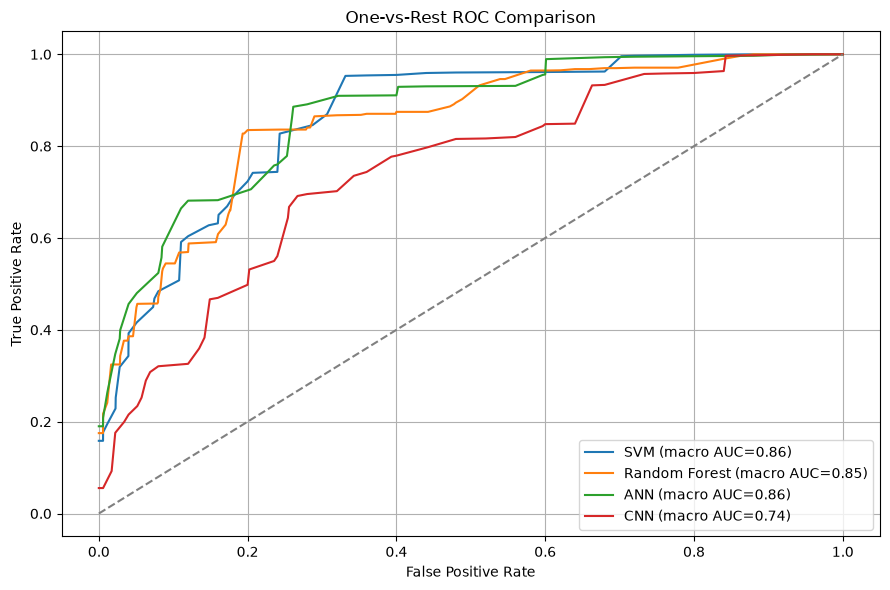

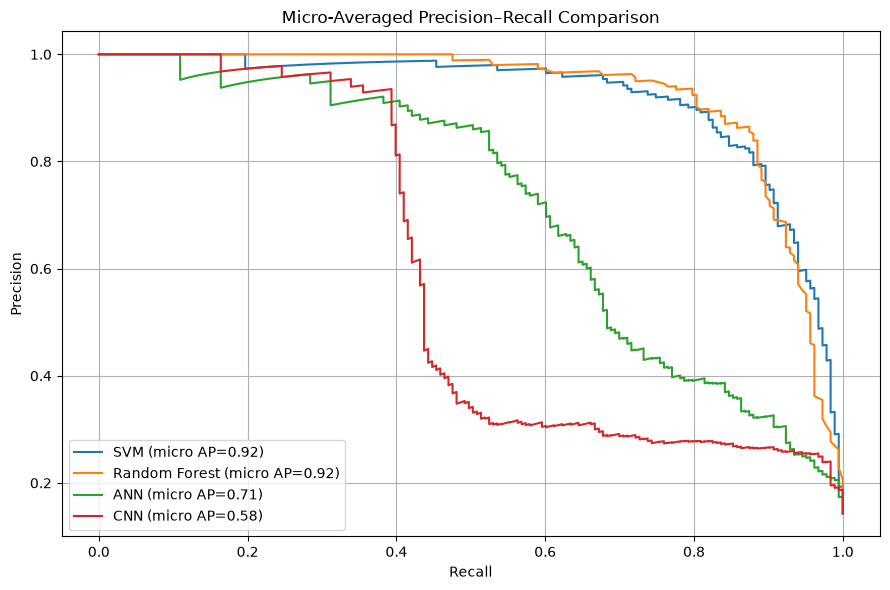

Saved ROC and precision-recall figures.


In [55]:
# Multiclass one-vs-rest ROC and micro-averaged precision-recall curves.
# Probability columns are aligned to the same sorted class order.
probabilities = {
    "SVM": svm_final.predict_proba(X_test_scaled),
    "Random Forest": rf_final.predict_proba(X_test_raw),
    "ANN": ann_prob_final,
    "CNN": cnn_prob_final
}
classes = label_encoder_final.classes_
y_test_bin = label_binarize(y_test, classes=classes)

fig, ax = plt.subplots(figsize=(9, 6))
for name, probs in probabilities.items():
    class_fprs, class_tprs, class_aucs = [], [], []
    for i in range(len(classes)):
        if len(np.unique(y_test_bin[:, i])) < 2:
            continue
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], probs[:, i])
        class_fprs.append(fpr)
        class_tprs.append(tpr)
        class_aucs.append(auc(fpr, tpr))
    if class_fprs:
        grid = np.unique(np.concatenate(class_fprs))
        mean_tpr = np.zeros_like(grid)
        for fpr, tpr in zip(class_fprs, class_tprs):
            mean_tpr += np.interp(grid, fpr, tpr)
        mean_tpr /= len(class_tprs)
        ax.plot(grid, mean_tpr, label=f"{name} (macro AUC={np.mean(class_aucs):.2f})")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="One-vs-Rest ROC Comparison")
ax.legend()
ax.grid(True)
fig.tight_layout()
fig.savefig("../results/roc_curve_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 6))
for name, probs in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test_bin.ravel(), probs.ravel())
    ap = average_precision_score(y_test_bin, probs, average="micro")
    ax.plot(recall, precision, label=f"{name} (micro AP={ap:.2f})")
ax.set(xlabel="Recall", ylabel="Precision", title="Micro-Averaged Precision–Recall Comparison")
ax.legend()
ax.grid(True)
fig.tight_layout()
fig.savefig("../results/precision_recall_curve_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved ROC and precision-recall figures.")

In [56]:
# Save final models and preprocessing objects.
joblib.dump(svm_final, "../models/svm_model.pkl")
joblib.dump(rf_final, "../models/random_forest_model.pkl")
joblib.dump(scaler_final, "../models/feature_scaler.pkl")
joblib.dump(label_encoder_final, "../models/label_encoder.pkl")
ann_final.save("../models/ann_model.keras")
cnn_final.save("../models/cnn_model.keras")

# Final consistency audit: accuracy must equal diagonal sum / test count.
print("\\nFINAL CONSISTENCY CHECK")
for name, pred in models_predictions.items():
    cm = confusion_matrix(y_test, pred, labels=classes)
    acc_from_predictions = accuracy_score(y_test, pred)
    acc_from_matrix = np.trace(cm) / cm.sum()
    print(f"{name}: {acc_from_predictions*100:.2f}% | confusion matrix: {np.trace(cm)}/{cm.sum()} | match={np.isclose(acc_from_predictions, acc_from_matrix)}")

print("\\nFinal artifacts saved to ../models and ../results.")

\nFINAL CONSISTENCY CHECK
SVM: 56.83% | confusion matrix: 104/183 | match=True
Random Forest: 86.34% | confusion matrix: 158/183 | match=True
ANN: 62.84% | confusion matrix: 115/183 | match=True
CNN: 49.18% | confusion matrix: 90/183 | match=True
\nFinal artifacts saved to ../models and ../results.


## Interpretation and limitations

- Report the newly generated `model_comparison.csv`; do not reuse accuracy values from earlier runs.
- Since the test split contains 159 COPD samples out of 184, overall accuracy is strongly influenced by COPD performance. Include macro F1 and per-class recall when discussing results.
- Minority classes have very few original recordings, and augmented copies do not replace collecting more independent patients.
- Results depend on this one split and do not establish clinical validity. Do not use this prototype to diagnose or guide treatment.
